# Predict New York City Airbnb Prices Using Linear Regression

## Project Objective

The main objective of this project is to predict the prices of Airbnb listings in New York City using Linear Regression.

In this project, we will explore the dataset, identify missing values, clean the data, handle outliers, select useful features, and convert categorical data into numerical form. We will then train and test a Linear Regression model and evaluate its performance using R-squared (R²), Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).

Finally, we will compare actual and predicted prices and check whether the model performs better for cheaper or more expensive listings.


In [1]:
#import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("AB_NYC_2019.csv")

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


### Types of Data in the Dataset

* **Numerical Discrete:** Values that can be counted, such as `number_of_reviews` and `minimum_nights`.
* **Numerical Continuous:** Values that can be measured, such as `latitude` and `longitude`.
* **Categorical Nominal:** Categories that have no natural order, such as `neighbourhood_group` and `room_type`.
* **Categorical Ordinal:** Categories that follow a meaningful order. The dataset does not contain an obvious ordinal feature among the columns used in this project.

These classifications help us understand the data before applying Linear Regression.


In [5]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [8]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [9]:

# Calculate missing values and their percentages
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percent
})

print(missing_summary[missing_summary["Missing Values"] > 0])

                   Missing Values  Missing Percentage (%)
name                           16                    0.03
host_name                      21                    0.04
last_review                 10052                   20.56
reviews_per_month           10052                   20.56


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
# Check the number of reviews for rows with missing reviews_per_month
missing_reviews = df["reviews_per_month"].isnull()

print(
    df.loc[missing_reviews, "number_of_reviews"]
    .value_counts(dropna=False)
)

number_of_reviews
0    10052
Name: count, dtype: int64


In [12]:
condition = (
    df["reviews_per_month"].isnull()
    & (df["number_of_reviews"] == 0)
)

df.loc[condition, "reviews_per_month"] = 0

In [13]:
if df["reviews_per_month"].isnull().any():
    median_value = df["reviews_per_month"].median()
    df["reviews_per_month"] = (
        df["reviews_per_month"].fillna(median_value)
    )

In [14]:
print("Missing values after cleaning:")

print(
    df[["reviews_per_month", "last_review"]]
    .isnull()
    .sum()
)

Missing values after cleaning:
reviews_per_month        0
last_review          10052
dtype: int64


In [15]:

df["reviews_per_month"] = df["reviews_per_month"].fillna(df["reviews_per_month"].median())


In [16]:
df = df.drop(columns=["id", "name", "host_id", "host_name", "last_review"],errors="ignore")

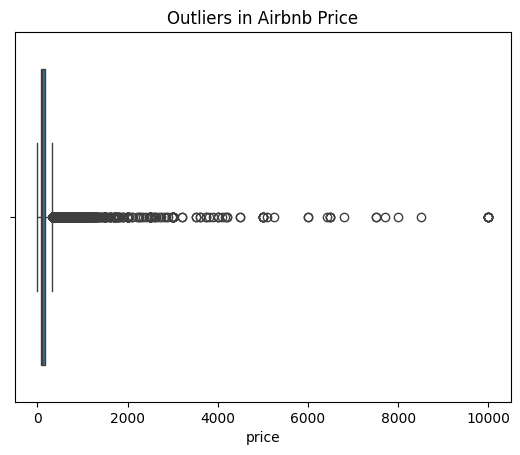

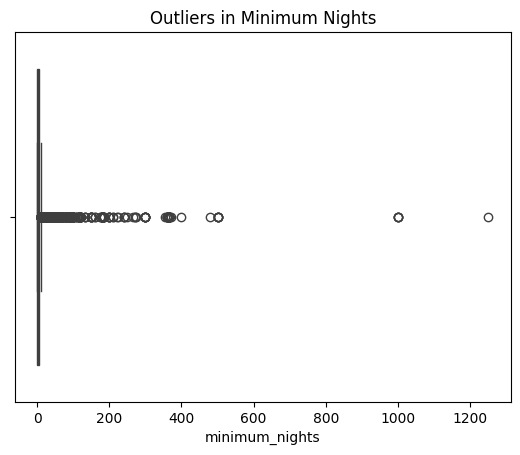

In [17]:
sns.boxplot(x=df["price"])
plt.title("Outliers in Airbnb Price")
plt.show()
sns.boxplot(x=df["minimum_nights"])
plt.title("Outliers in Minimum Nights")
plt.show()

In [18]:
# Calculate the 95th-percentile limits
price_limit = df["price"].quantile(0.95)
nights_limit = df["minimum_nights"].quantile(0.95)

# Count rows before filtering
rows_before = len(df)

# Remove extreme values
df = df[
    (df["price"] > 0) &
    (df["price"] <= price_limit) &
    (df["minimum_nights"] <= nights_limit) &
    (df["minimum_nights"] < 365)
].copy()

# Report the effect of filtering
print("95th percentile price limit:", price_limit)
print("95th percentile minimum nights limit:", nights_limit)
print("Rows before filtering:", rows_before)
print("Rows after filtering:", len(df))
print("Rows removed:", rows_before - len(df))

95th percentile price limit: 355.0
95th percentile minimum nights limit: 30.0
Rows before filtering: 48895
Rows after filtering: 45748
Rows removed: 3147


In [19]:
# Remove highly specific neighbourhood column
df = df.drop(columns=["neighbourhood"], errors="ignore")

# Select target variable
y = df["price"]

# Select input features
X = df.drop(columns=["price"])

# Convert categorical text into numeric columns
X = pd.get_dummies(
    X,
    columns=["neighbourhood_group", "room_type"],
    drop_first=True,
    dtype=int
)

print(X.head())
print(X.shape)

   latitude  longitude  minimum_nights  number_of_reviews  reviews_per_month  \
0  40.64749  -73.97237               1                  9               0.21   
1  40.75362  -73.98377               1                 45               0.38   
2  40.80902  -73.94190               3                  0               0.00   
3  40.68514  -73.95976               1                270               4.64   
4  40.79851  -73.94399              10                  9               0.10   

   calculated_host_listings_count  availability_365  \
0                               6               365   
1                               2               355   
2                               1               365   
3                               1               194   
4                               1                 0   

   neighbourhood_group_Brooklyn  neighbourhood_group_Manhattan  \
0                             1                              0   
1                             0                         

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(36598, 13)
(9150, 13)


In [22]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [23]:
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

print(results.head(10))

       Actual Price  Predicted Price
4948             80       107.114432
1629             73       145.833190
22548           186       184.774299
7886            150       166.007019
11047           229       140.962172
3941            180       157.897992
43706           180       145.200040
12574            49        72.325283
424             145       142.100589
15258            54        90.995701


In [24]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R-squared:", r2)
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

R-squared: 0.4867887874874506
Mean Absolute Error: 38.31554029954452
Mean Squared Error: 2760.6229553306853
Root Mean Squared Error: 52.54163068777638


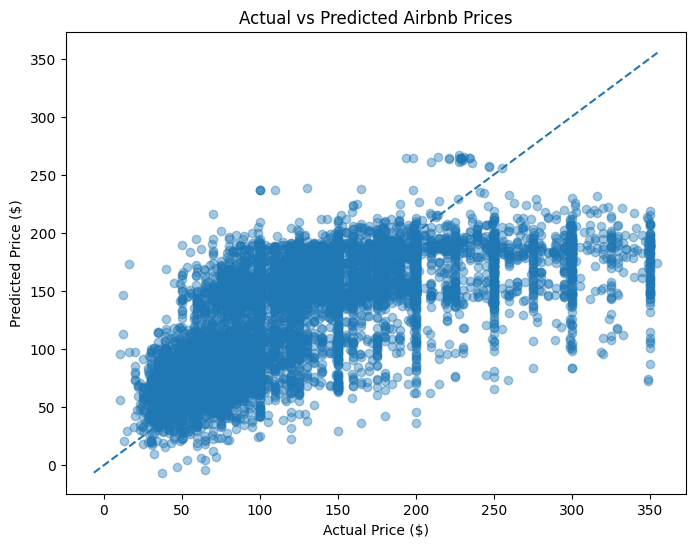

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Airbnb Prices")
plt.show()

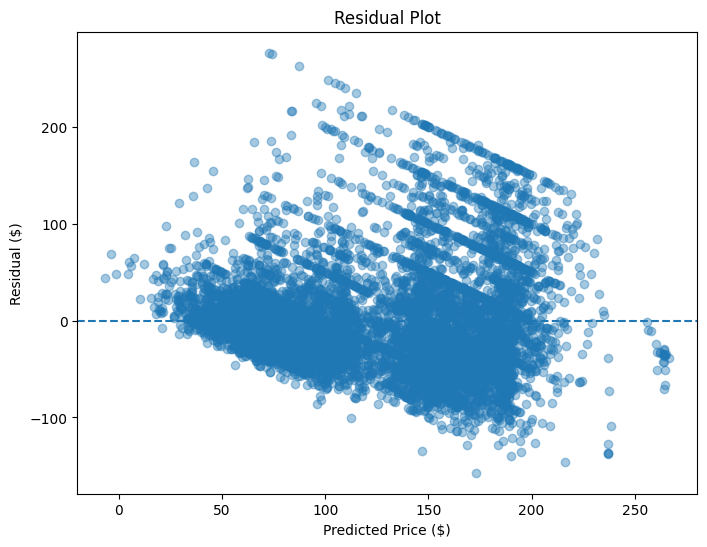

In [26]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residual Plot")
plt.show()

In [27]:
error_check = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

In [28]:
error_check["Absolute Error"] = (
    error_check["Actual"] - error_check["Predicted"]
).abs()

In [29]:
error_check["Price Group"] = np.where(
    error_check["Actual"] <= error_check["Actual"].median(),
    "Cheaper listings",
    "More expensive listings"
)

In [30]:
print(error_check.groupby("Price Group").agg(
    Mean_Absolute_Error=("Absolute Error", "mean"),
    Average_Actual_Price=("Actual", "mean")
))

                         Mean_Absolute_Error  Average_Actual_Price
Price Group                                                       
Cheaper listings                   29.012085             68.008709
More expensive listings            48.176113            182.671094


## Conclusion

In this project, we developed a Linear Regression model to predict Airbnb listing prices in New York City. We explored the dataset, handled missing values, removed irrelevant columns, treated outliers using the 95th-percentile method, and converted categorical features into numerical form.

The model was evaluated using a training set containing 80% of the data and a testing set containing 20% of the data.

* **R-squared (R²):** Approximately 0.487. This means the model explains about 48.7% of the variation in listing prices in the test data.
* **Mean Absolute Error (MAE):** Approximately $38.32. This means the model's predictions differ from the actual prices by about $38.32 per listing on average.
* **Root Mean Squared Error (RMSE):** Approximately $52.54. This measures prediction errors while giving more weight to larger errors.

The model performs better on cheaper listings. Their average absolute error is approximately $29.01, compared with a larger error for more expensive listings.

Overall, Linear Regression provides a useful starting point for predicting Airbnb prices, but its predictions are not exact. Other factors affecting listing prices may not be fully captured by the features used in this model.
